In [2]:
# loading the libraris
import pandas as pd
import tensorflow
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

In [3]:
import matplotlib.pyplot as plt
from sklearn import metrics

In [12]:
df = pd.read_csv("/content/Admission_Predict_Ver1.1.csv")

In [13]:
df.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,0.92
1,2,324,107,4,4.0,4.5,8.87,1,0.76
2,3,316,104,3,3.0,3.5,8.00,1,0.72
3,4,322,110,3,3.5,2.5,8.67,1,0.80
4,5,314,103,2,2.0,3.0,8.21,0,0.65


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Serial No.         500 non-null    int64  
 1   GRE Score          500 non-null    int64  
 2   TOEFL Score        500 non-null    int64  
 3   University Rating  500 non-null    int64  
 4   SOP                500 non-null    float64
 5   LOR                500 non-null    float64
 6   CGPA               500 non-null    float64
 7   Research           500 non-null    int64  
 8   Chance of Admit    500 non-null    float64
dtypes: float64(4), int64(5)
memory usage: 35.3 KB


In [15]:
df.isna().sum()

Serial No.           0
GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             0
Chance of Admit      0
dtype: int64

In [16]:
df.duplicated().sum()

0

In [18]:
df.columns

Index(['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP',
       'LOR ', 'CGPA', 'Research', 'Chance of Admit '],
      dtype='object')

In [19]:
# splitting the data into features and target
X = df.copy()
X.drop(["Serial No.","Chance of Admit "],axis=1,inplace=True)
y = df[["Chance of Admit "]]

In [56]:
from sklearn.preprocessing import MinMaxScaler


In [58]:
X = MinMaxScaler().fit_transform(X)

In [21]:
from sklearn.model_selection import train_test_split

In [59]:
# splitting the data into training and test set
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=21) 

In [98]:
# starting the ANN
model = Sequential()

# first layer
model.add(Dense(20,activation="relu",input_dim=7))

# second layer
model.add(Dense(15,activation="relu"))

# third layer
model.add(Dense(7,activation="relu"))

model.add(Dense(15,activation="relu"))

# Output layer, the activation function for linear regression in output layer is linear
model.add(Dense(1,activation="linear"))

In [99]:
# summary of model
model.summary()

Model: "sequential_8"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_27 (Dense)            (None, 20)                160       
                                                                 
 dense_28 (Dense)            (None, 15)                315       
                                                                 
 dense_29 (Dense)            (None, 7)                 112       
                                                                 
 dense_30 (Dense)            (None, 15)                120       
                                                                 
 dense_31 (Dense)            (None, 1)                 16        
                                                                 
Total params: 723
Trainable params: 723
Non-trainable params: 0
_________________________________________________________________


In [100]:
# compiling model
model.compile(loss="mean_squared_error",optimizer="Adam")

In [101]:
# fitting the model
history = model.fit(X_train,y_train,epochs=100,validation_split=0.2)

Epoch 1/100
10/10 [==============================] - 1s 17ms/step - loss: 0.0949 - val_loss: 0.0426
Epoch 2/100
10/10 [==============================] - 0s 4ms/step - loss: 0.0198 - val_loss: 0.0181
Epoch 3/100
10/10 [==============================] - 0s 4ms/step - loss: 0.0173 - val_loss: 0.0151
Epoch 4/100
10/10 [==============================] - 0s 5ms/step - loss: 0.0108 - val_loss: 0.0138
Epoch 5/100
10/10 [==============================] - 0s 4ms/step - loss: 0.0101 - val_loss: 0.0120
Epoch 6/100
10/10 [==============================] - 0s 4ms/step - loss: 0.0087 - val_loss: 0.0100
Epoch 7/100
10/10 [==============================] - 0s 7ms/step - loss: 0.0080 - val_loss: 0.0090
Epoch 8/100
10/10 [==============================] - 0s 4ms/step - loss: 0.0072 - val_loss: 0.0079
Epoch 9/100
10/10 [==============================] - 0s 4ms/step - loss: 0.0066 - val_loss: 0.0070
Epoch 10/100
10/10 [==============================] - 0s 4ms/step - loss: 0.0061 - val_loss: 0.0063
Epoch 11

In [102]:
# gettting prediction on the testing set
y_pred = model.predict(X_test)

4/4 [==============================] - 0s 3ms/step


In [103]:
import numpy as np

In [104]:
# computing r2_score and mean squared error
mse = np.sqrt(metrics.mean_squared_error(y_test,y_pred))

# computing r2_score
r2_scor = metrics.r2_score(y_test,y_pred)

In [105]:
mse

0.06698558440057065

In [108]:
r2_scor

0.7562700425048359

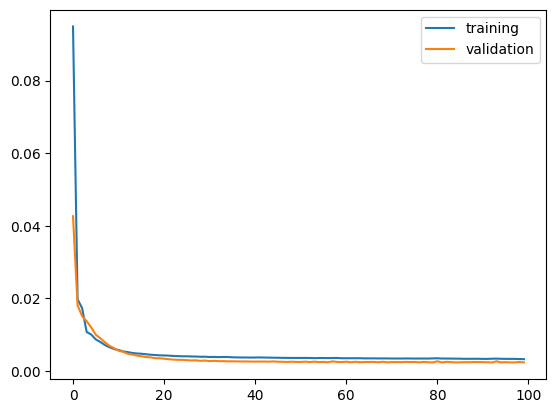

In [107]:
# plotting training and validation set loss
plt.plot(history.history['loss'],label="training")
plt.plot(history.history['val_loss'],label="validation")
plt.legend()